# Disagreements — Where do they disagree, and what needs review?

A **triple** connects a subject, a predicate, and an object: for example, “Paris — located in — France”. Raters a1 and a2 marked each criterion as **True = correct** or **False = incorrect**. A blank cell is a missing rating, not a rejection.

| Criterion | What does “correct” mean? | Where is the proposed correction? |
|---|---|---|
| Label (G) | Does the name match the Wikidata entity? | No dedicated column. |
| Entity (H) | Is the chosen entity appropriate? | I: proposed entity. |
| Predicate (J) | Is the chosen relation appropriate? | K: proposed predicate. |
| Direction (L) | Are subject and object in the right order? | M: proposed direction. |
| Fidelity to the text (N) | Does the triple express what the source text says? | O: comments. |

**The adjacent column contains a rater proposal, not a verified answer.** Column P (`rdf_final`) contains the complete final graph. The individual-triple corrected-RDF column was removed. Workbook headers and original evidence retain their source language.

The inputs retain the earlier a1 adjustment: in 296 rows, G=True led to J and L being set to True. Results describe these adjusted ratings, not a new independent annotation round.


**Rule:** if both say “incorrect” but propose different corrections, there is still a disagreement on the solution, even when all True/False judgments match.
See [Agreements.ipynb](Agreements.ipynb) for agreement metrics and the Jaccard explanation.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'ExamSource.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from the KGTestBench repository.')
sys.path.insert(0, str(ROOT/'ExamReview'))
import review_helpers as review
import rdf_comparison as rdf
import export_disagreements as export

INPUTS = {r: ROOT/'data/inter-rater-reliability'/f'{r}-rdf.xlsx' for r in ['a1','a2']}
SHEET = 'resultado_template_processado'
KEY = ['Identifier', 'tripla_original']
LABELS = {'label_corresponde_wikidata':'Label', 'entidade_correta':'Entity',
          'predicado_correto':'Predicate', 'direcao_relacao_correta':'Direction',
          'fidelidade_semantica':'Fidelity to the text'}
SUBSTANTIVE = {k:v for k,v in LABELS.items() if k != 'label_corresponde_wikidata'}
EXPECTED_COLUMNS = ['Identifier','Texto_Original','relacao_traduzida','RDF_Original',
    'tripla_original','posicao_no_texto','label_corresponde_wikidata','entidade_correta',
    'entidades_adequadas PREENCHER SE INCORRETO','predicado_correto',
    'predicados_adequados PREENCHER SE INCORRETO','direcao_relacao_correta',
    'direcao_relacoes_adequada PREENCHER SE INCORRETO','fidelidade_semantica','observacao','rdf_final']
hashes = {r: review.file_sha256(p) for r,p in INPUTS.items()}
for path in INPUTS.values():
    if pd.read_excel(path, sheet_name=SHEET, nrows=0).columns.tolist() != EXPECTED_COLUMNS:
        raise ValueError(f'{path.name}: the 16 column names or their order differ from the expected schema.')
loaded = {r:review.load_review(p,SHEET,KEY,list(LABELS)) for r,p in INPUTS.items()}
paired = review.align_reviews(loaded['a1'][0],loaded['a2'][0],KEY)
common = review.shared_items(paired,KEY)
relationships = common.loc[common.item_type=='relationship'].copy()
label_items = common.loc[common.item_type=='label'].copy()
whole = review.whole_triple_agreement(relationships,list(SUBSTANTIVE))
plt.rcParams.update({'font.size':11,'figure.dpi':120})
pd.set_option('display.max_colwidth',160)
COLORS = ['#285f91','#bd7225','#777777','#8765a3','#57836a']

def table(frame):
    display(frame.style.hide(axis='index').format(precision=3,na_rep='undefined'))

def bars(names, values, title, xlabel='Triples (count)', percent=False):
    fig, ax = plt.subplots(figsize=(10,max(3,len(names)*.55)),layout='constrained')
    values = np.asarray(values,dtype=float)
    ax.barh(list(names),values,color=COLORS[0])
    for i,v in enumerate(values):
        if np.isfinite(v): ax.text(v+.7,i,f'{v:.1f}%' if percent else f'{v:g}',va='center')
    finite = values[np.isfinite(values)]
    ax.set(xlabel=xlabel,title=title,xlim=(0,112 if percent else max(1,max(finite,default=0))*1.2))
    ax.invert_yaxis()
    plt.show()

def stacked(frame, columns, names, title):
    fig, ax = plt.subplots(figsize=(11,max(4,len(frame)*.6)),layout='constrained')
    left = np.zeros(len(frame))
    for col,name,color in zip(columns,names,COLORS):
        counts = frame[col].to_numpy(dtype=int)
        ax.barh(frame.index.astype(str),counts,left=left,label=name,color=color)
        for i,v in enumerate(counts):
            if v >= 4: ax.text(left[i]+v/2,i,str(v),ha='center',va='center',color='white',fontsize=10)
        left += counts
    ax.set(title=title,xlabel='Triples with both ratings (count)')
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
    plt.show()

display(Markdown(f"**Inputs:** {len(common)} paired items: {len(label_items)} labels and {len(relationships)} relationships. {(paired['_merge']!='both').sum()} unmatched items. Both workbooks have the same 16 columns."))

**Inputs:** 592 paired items: 297 labels and 295 relationships. 0 unmatched items. Both workbooks have the same 16 columns.

## 1. Which criteria does one rater approve and the other reject?

We count complete pairs only. Missing ratings are pending information, not confirmed disagreements.
The label criterion uses label triples; the other criteria use relationship triples.

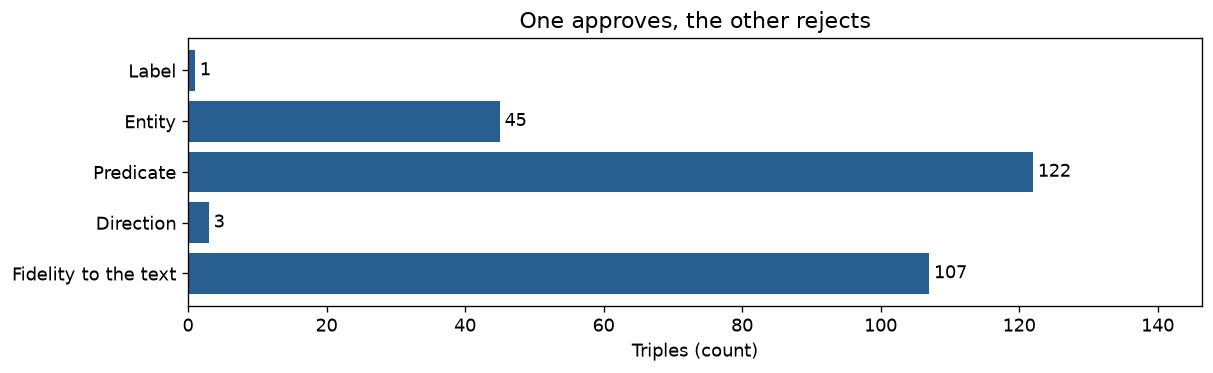

Criterion,Disagreements,Pairs,Incomplete pairs
Label,1,297,0
Entity,45,295,0
Predicate,122,295,0
Direction,3,295,0
Fidelity to the text,107,295,0


**Answer:** Predicate has 122 disagreements in 295 complete pairs. A triple may contribute to more than one criterion.

In [2]:
rows=[]
for c,name in LABELS.items():
    frame=label_items if c=='label_corresponde_wikidata' else relationships
    m=review.metrics(frame,c,name)
    rows.append({'Criterion':name,'Disagreements':m['disagreements'],'Pairs':m['n_pairs'],
                 'Incomplete pairs':m['n_shared_items']-m['n_pairs']})
rating_disagreements=pd.DataFrame(rows)
bars(rating_disagreements['Criterion'],rating_disagreements['Disagreements'],'One approves, the other rejects')
table(rating_disagreements)
top=rating_disagreements.sort_values('Disagreements',ascending=False).iloc[0]
display(Markdown(f"**Answer:** {top['Criterion']} has {top['Disagreements']} disagreements in {top['Pairs']} complete pairs. A triple may contribute to more than one criterion."))

## 2. Both say “incorrect”: are their diagnoses different?

Disagreeing about **what is wrong** and **how to fix it** are separate issues.
First, we compare the sets of rejected criteria, using relationships with all eight ratings present.

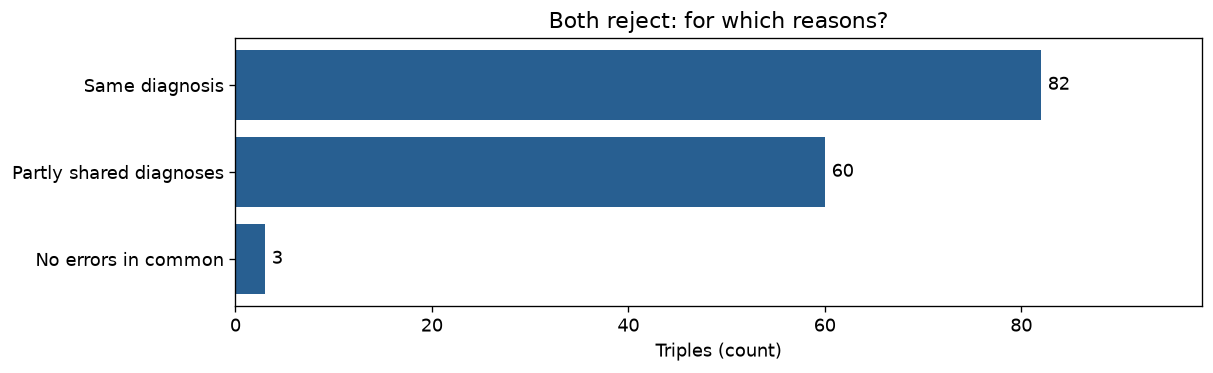

**Answer:** 63 of 145 jointly rejected relationships have different diagnoses. The other 82 share a diagnosis, but their proposed corrections still need comparison.

In [3]:
joint=review.joint_error_details(relationships,SUBSTANTIVE)
same=int(joint.same_error_set.sum())
partial=int((joint.shared_error_count.gt(0)&~joint.same_error_set).sum())
none=int(joint.shared_error_count.eq(0).sum())
bars(['Same diagnosis','Partly shared diagnoses','No errors in common'],[same,partial,none],
     'Both reject: for which reasons?')
display(Markdown(f"**Answer:** {partial+none} of {len(joint)} jointly rejected relationships have different diagnoses. The other {same} share a diagnosis, but their proposed corrections still need comparison."))

## 3. Does the adjacent column contain the correction? Do they propose the same thing?

Columns I, K, and M contain **proposed entities, predicates, and directions**, not a verified answer key.
We compare fields whose criterion was rejected by at least one rater, within relationships where both found at least one error.

- **Different text:** a proposed-correction disagreement to review, even when judgments match.
- **Same text:** identical written proposals; this does not prove factual correctness.
- **Only one filled in / both blank:** missing information, not two competing proposals.

Only extra whitespace and equivalent Unicode forms are ignored. Synonyms or different wording may express the same solution; a human reviewer decides. Each bar counts **correction fields**, not unique triples.

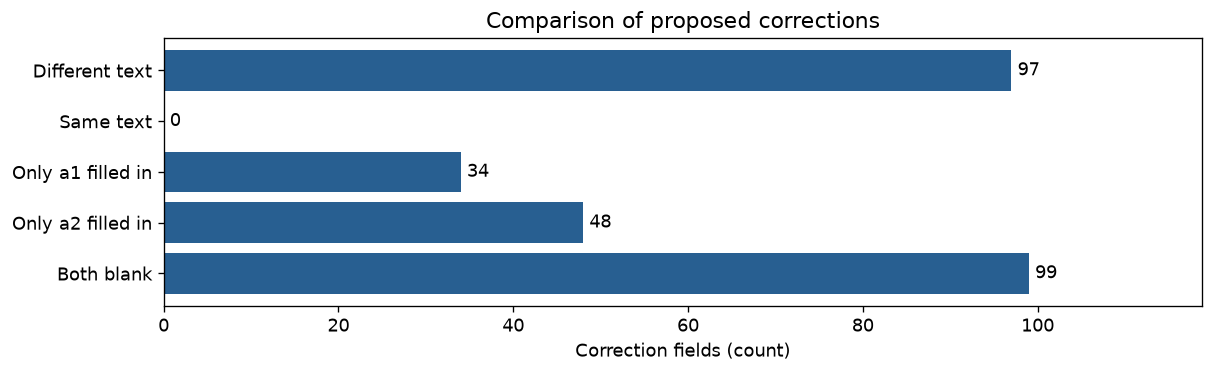

**Answer:** 97 relationships have at least one differently written proposal. Of these, 58 have identical judgments on all four criteria but different correction text. Only one rater filled in a suggestion in 82 fields.

**Real examples — proposals side by side (up to 5; source wording preserved):**

Identifier,criterion,a1,a2
Amazon,Entity,sujeito: wd:Q3884; objeto: wd:Q12737077,technology company
Amazon,Entity,objeto: não determinada,American
Amazon,Entity,objeto: não determinada,American
Amazon,Entity,objeto: não determinada,artificial intelligence
Amazon,Predicate,kg:engage,-be->


In [4]:
correction_rows=[]
for _,row in relationships.iterrows():
    a,b=[export.ratings(row,r) for r in ['a1','a2']]
    if not (any(v is False for v in a.values()) and any(v is False for v in b.values())): continue
    for item in export.correction_comparisons(row):
        correction_rows.append({'Identifier':row.Identifier,'tripla_original':row.tripla_original,
            'criterion':LABELS[item['criterion']],'a1':item['a1'],'a2':item['a2'],'status':item['status'],
            'mesmos_julgamentos':all(v is not None for v in [*a.values(), *b.values()])
                and all(a[c]==b[c] for c in SUBSTANTIVE)})
corrections=pd.DataFrame(correction_rows,columns=['Identifier','tripla_original','criterion','a1','a2','status','mesmos_julgamentos'])
status_names={'different':'Different text','same_text':'Same text','only_a1':'Only a1 filled in',
              'only_a2':'Only a2 filled in','both_missing':'Both blank'}
correction_counts=corrections.status.value_counts().reindex(status_names,fill_value=0)
bars(list(status_names.values()),correction_counts,'Comparison of proposed corrections','Correction fields (count)')
different=corrections.loc[corrections.status=='different'].copy()
different_items=different.drop_duplicates(KEY)
same_ratings=different.loc[different.mesmos_julgamentos].drop_duplicates(KEY)
display(Markdown(f"**Answer:** {len(different_items)} relationships have at least one differently written proposal. Of these, {len(same_ratings)} have identical judgments on all four criteria but different correction text. Only one rater filled in a suggestion in {int(correction_counts.only_a1+correction_counts.only_a2)} fields."))
if len(different):
    display(Markdown("**Real examples — proposals side by side (up to 5; source wording preserved):**"))
    table(different[['Identifier','criterion','a1','a2']].head(5))

## 4. When an entity was unresolved, did both raters record it?

We look for phrases such as “não determinada” (“not determined”) in entity suggestions.
Without an explicit marker, we do not know whether a search occurred or succeeded. This is an annotation, not an API log.

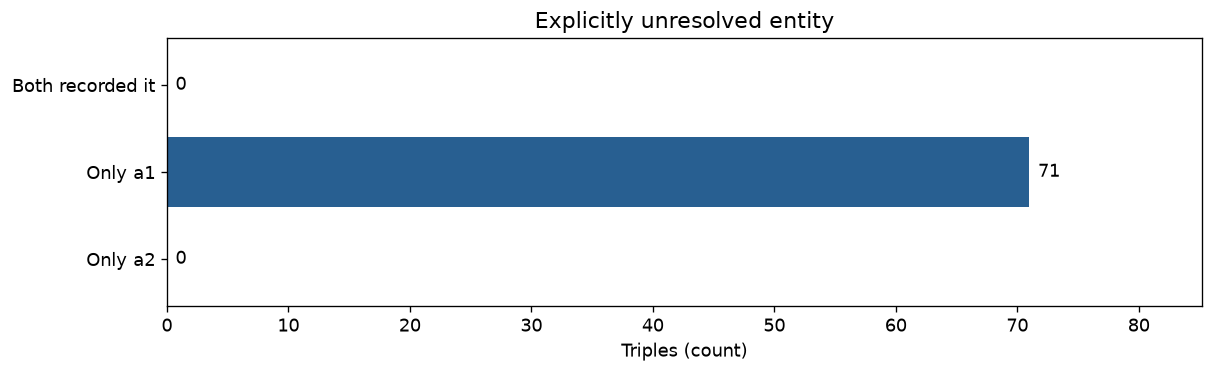

**Answer:** both recorded difficulty in 0 relationships; only one did so in 71. A missing marker from the other rater does not confirm successful resolution.

In [5]:
u1=review.unresolved_flags(relationships,'a1'); u2=review.unresolved_flags(relationships,'a2')
unresolved_counts=[int((u1&u2).sum()),int((u1&~u2).sum()),int((~u1&u2).sum())]
bars(['Both recorded it','Only a1','Only a2'],unresolved_counts,'Explicitly unresolved entity')
display(Markdown(f"**Answer:** both recorded difficulty in {unresolved_counts[0]} relationships; only one did so in {sum(unresolved_counts[1:])}. A missing marker from the other rater does not confirm successful resolution."))

## 5. Do the final graphs contain different solutions?

We compare `rdf_final` relationships within each group. An identical relationship requires the same subject, predicate, and object.
An exclusive relationship may reflect an addition, removal, or change; the difference alone does not tell us who is right.
For an overall overlap score, use the **Jaccard explanation in [Agreements.ipynb](Agreements.ipynb)**.

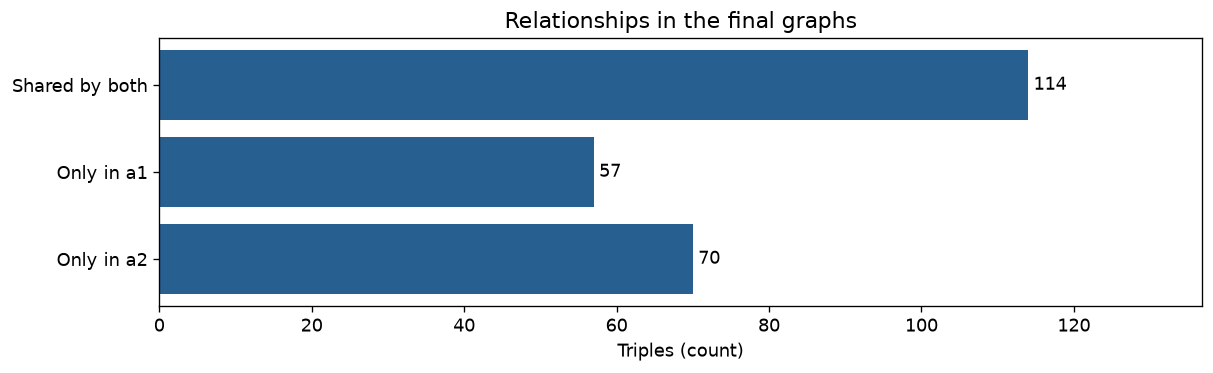

**Answer:** 114 relationships are identical; 57 occur only in a1 and 70 only in a2. The source text should guide the choice of solution.

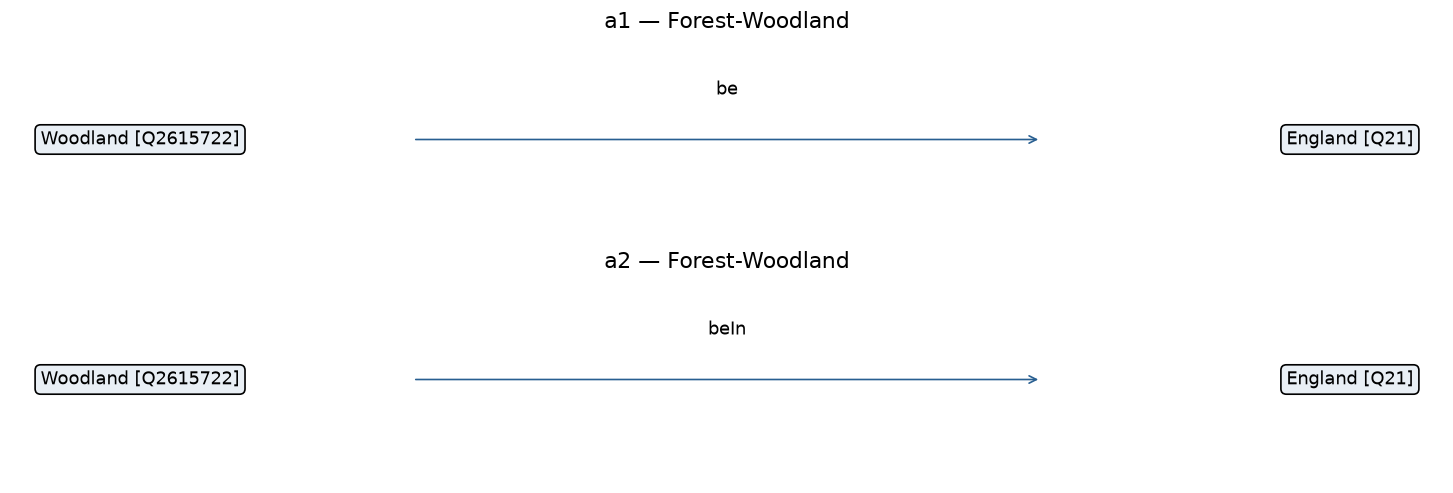

**Example:** the same entities are linked by different predicates. This is a possible solution difference, not a confirmed replacement.

In [6]:
graphs={r:rdf.load_final_graphs(p,'rdf_final')[0] for r,p in INPUTS.items()}
graph_by_group,graph_totals=rdf.compare_graphs(graphs['a1'],graphs['a2'])

r=graph_totals.set_index('dimension').loc['Relation triples']
bars(['Shared by both','Only in a1','Only in a2'],[r.shared,r.only_a1,r.only_a2],
     'Relationships in the final graphs')
graph_candidates=rdf.mismatch_candidates(graphs['a1'],graphs['a2'])
examples=graph_candidates.loc[(graph_candidates.source=='a1')&(graph_candidates.kind=='Predicate only')].head(1)
display(Markdown(f"**Answer:** {int(r.shared)} relationships are identical; {int(r.only_a1)} occur only in a1 and {int(r.only_a2)} only in a2. The source text should guide the choice of solution."))
if len(examples):
    import rdflib
    example=examples.iloc[0]
    triples=[]
    for field,side in [('triple','a1'),('candidate','a2')]:
        terms=[rdflib.util.from_n3(t) for t in example[field]]
        triples.append([rdf.display_term(t,graphs[side][example.Identifier]) for t in terms])
    fig,axes=plt.subplots(2,1,figsize=(12,4),layout='constrained')
    import textwrap
    for ax,side,(s,p,o) in zip(axes,['a1','a2'],triples):
        ax.axis('off')
        ax.text(.02,.5,textwrap.fill(s,24),ha='left',va='center',bbox={'boxstyle':'round','fc':'#e9eff5'})
        ax.text(.98,.5,textwrap.fill(o,24),ha='right',va='center',bbox={'boxstyle':'round','fc':'#e9eff5'})
        ax.annotate('',xy=(.72,.5),xytext=(.28,.5),arrowprops={'arrowstyle':'->','color':COLORS[0]})
        ax.text(.5,.7,textwrap.fill(p,40),ha='center',va='bottom')
        ax.set_title(f'{side} — {example.Identifier}')
    plt.show()
    display(Markdown("**Example:** the same entities are linked by different predicates. This is a possible solution difference, not a confirmed replacement."))

## 6. Which original triples need review?

The CSV has **one row per Identifier and original triple**. Each numbered block contains a disagreement criterion and the source decisions: `disagreement_type_1`, `a1_decision_1`, `a2_decision_1`, **`decision_1`**, then `_2`, `_3`, and so on. Each `decision_N` starts blank and is reserved for your review decision. It is not filled automatically by the source-rating rules below.

- **TRUE:** this rater approved the criterion while the other rejected it.
- **FALSE:** this rater rejected semantic fidelity and the entity-removal rule does not apply.
- **Original text:** the rater supplied a correction; its wording is preserved.
- **remove:** this rater marked the entity incorrect and left its correction blank. Under the export rule, their other empty decisions for this triple also become `remove`.
- **Blank:** no suggestion was supplied and the removal rule does not apply. Entirely unused blocks also remain blank.

The removal rule applies independently to each rater and does not overwrite a written correction or TRUE. It is an export rule, not text added to the source workbooks. Semantic fidelity has no dedicated correction field, so its rejecting side is `FALSE`, or `remove` when the entity-removal rule applies. Missing source ratings remain missing.

Each criterion appears at most once per triple. A triple may occur in several bars. Final-graph differences remain in section 5 because they do not always identify a specific original triple.


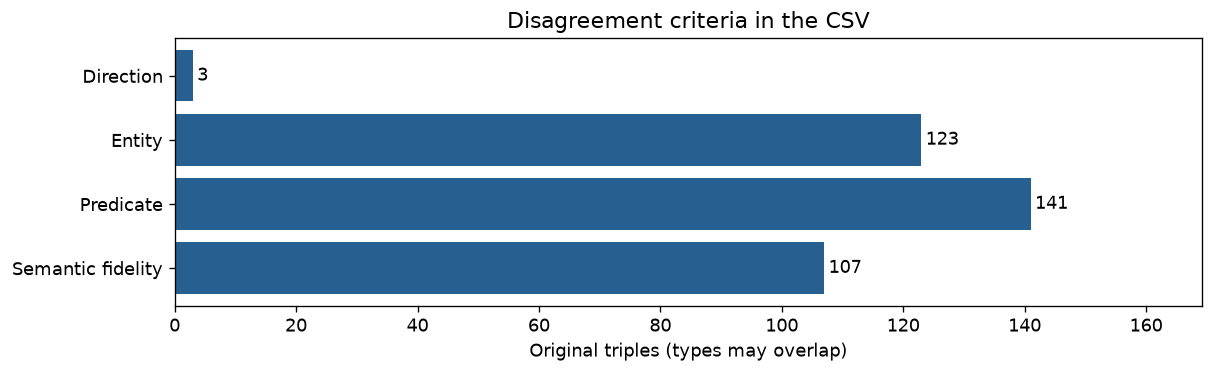

**Answer:** the CSV contains 215 original triples, with up to 3 disagreement blocks per row. 97 triples include different correction text after both raters reject. Blank blocks mean the triple has no additional selected disagreement. Missing suggestions alone are not competing proposals.

identifier,disagreement_type_1,a1_decision_1,a2_decision_1,decision_1
Amazon,Entity,sujeito: wd:Q3884; objeto: wd:Q12737077,technology company,
Amazon,Predicate,TRUE,-be->,
Amazon,Entity,objeto: não determinada,American,


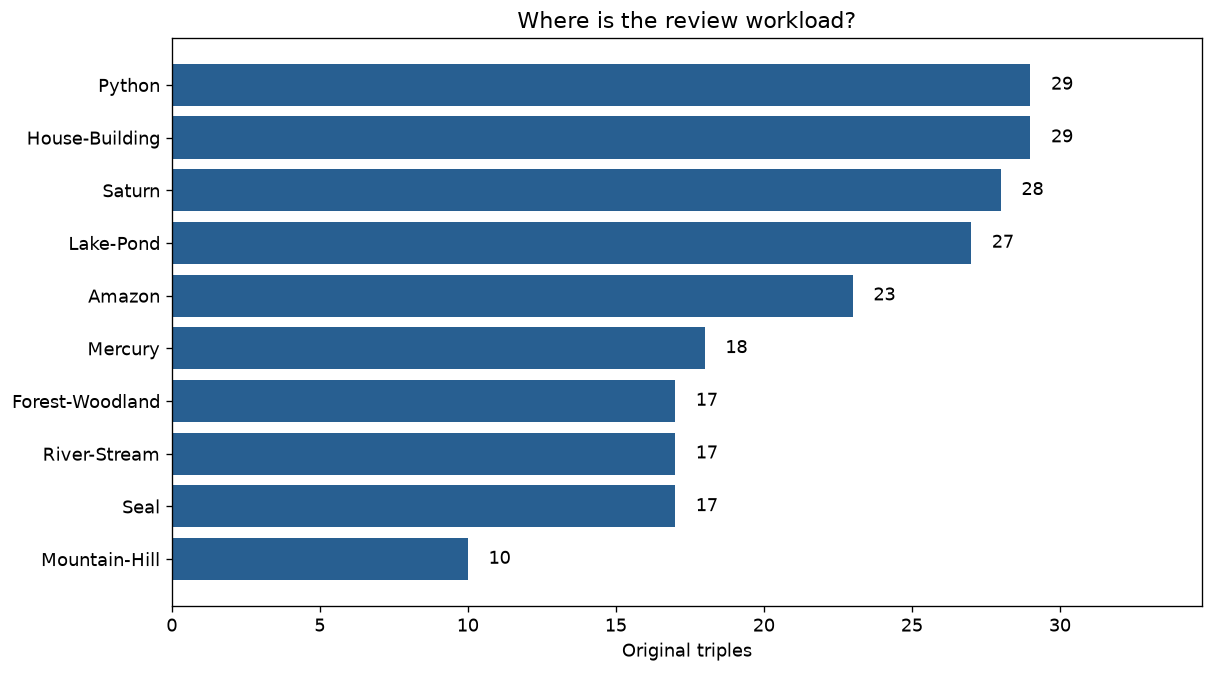

**Where to start:** Python has 29 original triples to review. Use the count to organize the workload, not to rank factual correctness.

In [7]:
CSV_PATH = ROOT/'data/disagreements.csv'
csv_hash = review.file_sha256(CSV_PATH)
case_table = pd.read_csv(CSV_PATH, encoding='utf-8-sig', dtype=str, keep_default_na=False)
expected_csv = export.build_export(INPUTS['a1'], INPUTS['a2'])
source_columns = [c for c in expected_csv if not c.startswith('decision_')]
try:
    assert case_table.columns.tolist() == expected_csv.columns.tolist(), 'Unexpected CSV columns'
    pd.testing.assert_frame_equal(case_table[source_columns], expected_csv[source_columns], check_dtype=False)
except AssertionError as exc:
    raise ValueError('The CSV differs from the current source workbooks. Regenerate the export.') from exc

type_columns = [c for c in case_table if c.startswith('disagreement_type_')]
types = case_table[type_columns].melt(value_name='type')['type']
counts = types.loc[types.ne('')].value_counts().sort_index()
bars(counts.index, counts.values, 'Disagreement criteria in the CSV', 'Original triples (types may overlap)')

exported = set(map(tuple, case_table[
    ['identifier', 'original_triple']
].itertuples(index=False, name=None)))
expected = set(map(tuple, different_items[KEY].itertuples(index=False, name=None)))
assert expected <= exported
assert not case_table.duplicated(['identifier', 'original_triple']).any()

display(Markdown(
    f'**Answer:** the CSV contains {len(case_table)} original triples, with up to {len(type_columns)} '
    f'disagreement blocks per row. {len(expected)} triples include different correction text after both raters reject. '
    'Blank blocks mean the triple has no additional selected disagreement. Missing suggestions alone are not competing proposals.'
))
table(case_table[['identifier', 'disagreement_type_1', 'a1_decision_1', 'a2_decision_1', 'decision_1']].head(3))
groups = case_table.groupby('identifier').size().sort_values(ascending=False)
bars(groups.index, groups.values, 'Where is the review workload?', 'Original triples')
if len(groups):
    display(Markdown(f'**Where to start:** {groups.index[0]} has {groups.iloc[0]} original triples to review. '
                     'Use the count to organize the workload, not to rank factual correctness.'))


## What should I do with a disagreement?

1. Read `original_text` and `original_triple`.
2. Read each numbered disagreement block and compare `a1_decision` with `a2_decision`.
3. Check whether differently written suggestions mean the same thing.
4. Enter your review decision in the corresponding `decision_N` column. Leave the a1/a2 source decisions unchanged. TRUE records approval by that rater; other values are their original suggestions. A blank means no suggestion was supplied, not approval. The `remove` value follows the empty entity-correction rule described above.

The notebook only reads and checks the CSV. It does not update the source workbooks or final graphs.


The notebook accepts filled review-decision columns and leaves them unchanged. Running the exporter with `--overwrite` clears these manual decisions, so use a new output filename when they need to be retained.

In [8]:
assert all(review.file_sha256(p)==hashes[r] for r,p in INPUTS.items())
assert review.file_sha256(CSV_PATH)==csv_hash
display(Markdown('**Checks passed:** one row per original triple, CSV matches the sources, and all input files are unchanged.'))

**Checks passed:** one row per original triple, CSV matches the sources, and all input files are unchanged.